# Day 2: Baseline vs better models

Target: `log_price`. Split: 5-fold `GroupKFold` on `model`, so the same laptop never appears in both train and test. Errors are reported back in ₹.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import r2_score, mean_absolute_error
from xgboost import XGBRegressor

sns.set_theme(style="whitegrid")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(ROOT / "data" / "clean.csv")
df["Touch_Screen"] = df["Touch_Screen"].astype(int)

y = df["log_price"]
groups = df["model"]                      # used only to split, never as a feature
X = df.drop(columns=["price", "log_price", "model"])

cat_cols = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
num_cols = [c for c in X.columns if c not in cat_cols]
print(len(df), "rows |", len(cat_cols), "categorical,", len(num_cols), "numeric features")
print("unique model names (groups):", groups.nunique())
print(cat_cols)

940 rows | 8 categorical, 12 numeric features
unique model names (groups): 881
['brand_name', 'processor_brand', 'iter', 'memory_type', 'gpu_brand', 'gpu_type', 'os', 'gpu_family']


## 1. Models

Ridge is the baseline (scaled numeric features). Random Forest and XGBoost are the better models.

In [2]:
def make_pre(scale):
    num = StandardScaler() if scale else "passthrough"
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
        ("num", num, num_cols),
    ])

models = {
    "Ridge (baseline)": Pipeline([("pre", make_pre(True)), ("m", Ridge(alpha=1.0))]),
    "Random Forest": Pipeline([("pre", make_pre(False)),
                               ("m", RandomForestRegressor(n_estimators=300, min_samples_leaf=2,
                                                           random_state=42, n_jobs=-1))]),
    "XGBoost": Pipeline([("pre", make_pre(False)),
                         ("m", XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=4,
                                            subsample=0.8, colsample_bytree=0.8,
                                            random_state=42, n_jobs=-1))]),
}

## 2. Cross-validated results (5-fold GroupKFold)

In [3]:
cv = GroupKFold(n_splits=5)
rows, preds = [], {}
for name, pipe in models.items():
    p = cross_val_predict(pipe, X, y, cv=cv, groups=groups)
    preds[name] = p
    price_true, price_pred = np.exp(y), np.exp(p)
    rows.append({
        "model": name,
        "R2 (log price)": r2_score(y, p),
        "MAE (₹)": mean_absolute_error(price_true, price_pred),
        "Median % error": np.median(np.abs(price_pred - price_true) / price_true) * 100,
    })

results = pd.DataFrame(rows).set_index("model").round(3)
results.to_csv(ROOT / "reports" / "model_results.csv")
results

,R2 (log price),MAE (₹),Median % error
model,,,
Ridge (baseline),0.897,15122.657,9.769
Random Forest,0.903,13353.968,8.987
XGBoost,0.922,12035.811,8.477


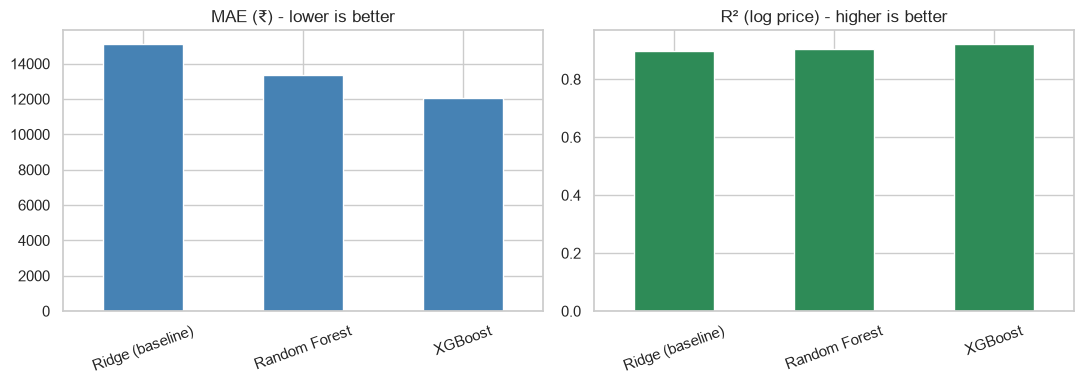

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
results["MAE (₹)"].plot.bar(ax=ax[0], color="steelblue"); ax[0].set_title("MAE (₹) - lower is better")
results["R2 (log price)"].plot.bar(ax=ax[1], color="seagreen"); ax[1].set_title("R² (log price) - higher is better")
for a in ax: a.tick_params(axis="x", rotation=20); a.set_xlabel("")
plt.tight_layout(); plt.savefig(FIG / "model_comparison.png", dpi=150); plt.show()

## 3. Predicted vs actual (best model by MAE)

best model: XGBoost


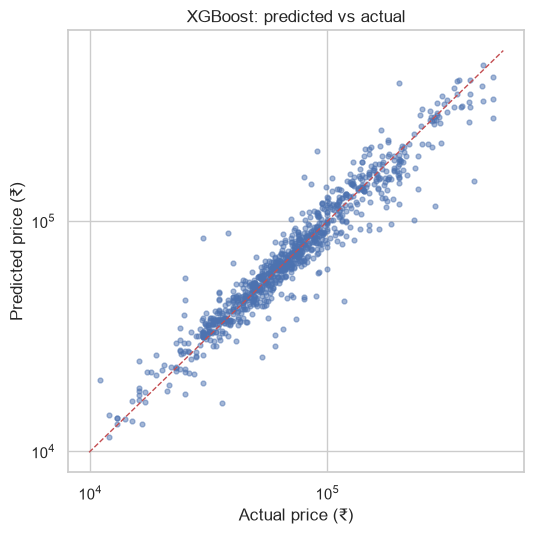

In [5]:
best = results["MAE (₹)"].idxmin()
print("best model:", best)
plt.figure(figsize=(5.5, 5.5))
plt.scatter(np.exp(y), np.exp(preds[best]), s=12, alpha=0.5)
lim = [df.price.min() * 0.9, df.price.max() * 1.1]
plt.plot(lim, lim, "r--", lw=1)
plt.xscale("log"); plt.yscale("log")
plt.xlabel("Actual price (₹)"); plt.ylabel("Predicted price (₹)"); plt.title(f"{best}: predicted vs actual")
plt.tight_layout(); plt.savefig(FIG / "predicted_vs_actual.png", dpi=150); plt.show()

In [ ]:
err = pd.DataFrame({"price": np.exp(y), "pred": np.exp(preds[best])})
err["abs_err"] = (err.pred - err.price).abs()
err["pct_err"] = err.abs_err / err.price * 100
err["band"] = pd.qcut(err.price, 4, labels=["Q1 lowest", "Q2", "Q3", "Q4 highest"])
err.groupby("band", observed=True).agg(
    price_from=("price", "min"), price_to=("price", "max"),
    median_pct_err=("pct_err", "median"), MAE=("abs_err", "mean")).round(1)

,price_from,price_to,median_pct_err,MAE
band,,,,
Q1 cheapest,10990.0,45490.0,8.9,4205.7
Q2,45800.0,66990.0,7.1,5195.6
Q3,66999.0,99990.0,7.0,9546.3
Q4 priciest,99999.0,500990.0,12.0,29214.1


## Findings (fill in)

- How much better is XGBoost / Random Forest than the Ridge baseline (MAE in ₹ and R²)?
- Typical error in % terms?
- Where does the best model do worst (cheap, mid-range or very expensive laptops)?

Next: Day 3 – SHAP explanations and the fair price check.

## Findings

- **Baseline is already strong.** A scaled Ridge regression on log price reaches R² 0.897 with a MAE of about ₹15.1k, so the engineered features (RAM, storage, GPU model, resolution) carry most of the signal.
- **XGBoost is best.** It cuts MAE from ₹15.1k to ₹12.0k (about 20% lower than the baseline) and raises R² to 0.922. Random Forest sits in between at ₹13.4k (about 12% lower).
- **Typical error is about 8.5%.** The median error is roughly ₹5-6k on a laptop at the median price of about ₹67k.
- **Honest split.** Evaluation uses 5-fold GroupKFold on laptop model name, so the same laptop never appears in both train and test.
- **Caveat.** With 940 listings, the gap between Random Forest and XGBoost (about ₹1.3k MAE) is small and could change with a different split. The gap between Ridge and XGBoost is larger.